In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import mode
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Загрузка данных
wine = load_wine()
X = wine.data
y = wine.target
k = len(set(y))


# Функции привязки и обновления центроидов
def assign_clusters(X, centroids):
  distances = np.linalg.norm(X[:, np.newaxis] - centroids, axis=2)
  return np.argmin(distances, axis=1)


def update_centroids(X, labels, k):
  new_centroids = np.zeros((k, X.shape[1]))
  for j in range(k):
    cluster_points = X[labels == j]
    if len(cluster_points) > 0:
      new_centroids[j] = cluster_points.mean(axis=0)
  return new_centroids


def calculate_wss(X, labels, centroids):
  wss = 0.0
  for j in range(k):
    cluster_points = X[labels == j]
    if len(cluster_points) > 0:
      wss += np.sum((cluster_points - centroids[j]) ** 2)
  return wss


# 3. Функция сопоставления номеров кластеров реальным сортам вина
def map_clusters_to_classes(y_train, train_clusters, test_clusters, k):
  mapping = {}
  for j in range(k):
    mask = train_clusters == j
    if np.any(mask):
      # Какой реальный сорт чаще всего встречается в кластере j на обучении
       mapping[j] = mode(y_train[mask], keepdims=True).mode[0]
    else:
      mapping[j] = 0
  # Переводим номера кластеров теста в реальные сорта
  mapped_test = np.array([mapping[c] for c in test_clusters])
  return mapped_test


In [2]:
def fit_kmeans_step_by_step(
    X, k, seed=123, max_iter=50, tol=1e-6, verbose=True
):
  rng = np.random.default_rng(seed=seed)
  num_rows = X.shape[0]

  # Начальное разбиение
  init_indices = rng.choice(num_rows, size=k, replace=False)
  centroids = X[init_indices, :]
  labels = assign_clusters(X, centroids)

  wss_history = []

  if verbose:
    print(f"--- Запуск алгоритма (seed={seed}) ---")

  for i in range(max_iter):
    old_centroids = centroids.copy()

    # 1. В начале вычисляются центры кластеров
    centroids = update_centroids(X, labels, k)

    # 2. Затем вычисляется новое разбиение кластеров
    labels = assign_clusters(X, centroids)

    # Считаем сдвиг центров и WSS для демонстрации сходимости
    shift = np.linalg.norm(centroids - old_centroids)
    wss = calculate_wss(X, labels, centroids)
    wss_history.append(wss)

    if verbose:
      counts = np.bincount(labels, minlength=k)
      print(
          f"Этап {i+1}: WSS = {wss:.2f} | Сдвиг центров = {shift:.6f} | Размеры"
          f" кластеров: {counts}"
      )

    if shift < tol:
      if verbose:
        print(f"Алгоритм сошелся на {i+1} этапе.\n")
      break

  return centroids, labels, wss_history


--- Запуск алгоритма (seed=123) ---
Этап 1: WSS = 1036.24 | Сдвиг центров = 3.943579 | Размеры кластеров: [32 57 53]
Этап 2: WSS = 1026.92 | Сдвиг центров = 0.461387 | Размеры кластеров: [33 56 53]
Этап 3: WSS = 1025.26 | Сдвиг центров = 0.163793 | Размеры кластеров: [34 55 53]
Этап 4: WSS = 1024.17 | Сдвиг центров = 0.155991 | Размеры кластеров: [34 55 53]
Этап 5: WSS = 1024.17 | Сдвиг центров = 0.000000 | Размеры кластеров: [34 55 53]
Алгоритм сошелся на 5 этапе.



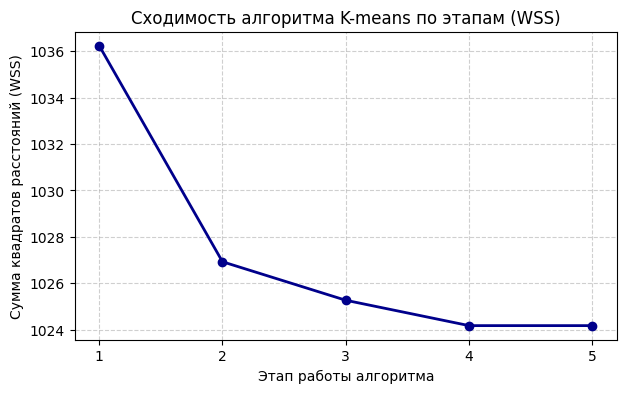

In [3]:
# Пробный запуск 
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=123)
scaler = StandardScaler()
X_tr_std = scaler.fit_transform(X_tr)
X_te_std = scaler.transform(X_te)

final_centroids, train_labels, wss_hist = fit_kmeans_step_by_step(
    X_tr_std, k, seed=123, verbose=True
)

# График сходимости (по этапам)
plt.figure(figsize=(7, 4))
plt.plot(
    range(1, len(wss_hist) + 1),
    wss_hist,
    marker='o',
    color='darkblue',
    linewidth=2,
)
plt.title('Сходимость алгоритма K-means по этапам (WSS)')
plt.xlabel('Этап работы алгоритма')
plt.ylabel('Сумма квадратов расстояний (WSS)')
plt.xticks(range(1, len(wss_hist) + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


In [4]:
# Задаем разные доли тестовой выборки для нескольких запусков
test_sizes = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
results = []

for idx, t_size in enumerate(test_sizes, 1):
  # Делим выборку
  X_tr, X_te, y_tr, y_te = train_test_split(
      X, y, test_size=t_size, random_state=42 + idx
  )

  # Масштабируем
  scaler = StandardScaler()
  X_tr_std = scaler.fit_transform(X_tr)
  X_te_std = scaler.transform(X_te)

  # Обучаем K-means (без лишнего текста, verbose=False)
  cents, tr_labels, _ = fit_kmeans_step_by_step(
      X_tr_std, k, seed=123, verbose=False
  )

  # Предсказываем кластеры для тестовой выборки
  te_labels = assign_clusters(X_te_std, cents)

  # Сопоставляем кластеры с реальными сортами, чтобы посчитать правильные и неправильные ответы
  predicted_classes = map_clusters_to_classes(y_tr, tr_labels, te_labels, k)

  # Считаем показатели для таблицы
  n_train = len(X_tr)
  n_test = len(X_te)
  n_correct = np.sum(predicted_classes == y_te)
  n_incorrect = np.sum(predicted_classes != y_te)
  accuracy_pct = (n_correct / n_test) * 100

  results.append({
      '№ запуска': idx,
      'Общее кол-во в обуч. выборке': n_train,
      'Кол-во в тест. выборке': n_test,
      'Правильно кластеризовано': n_correct,
      'Неправильно кластеризовано': n_incorrect,
      'Точность (%)': round(accuracy_pct, 2),
  })

# Формируем итоговую таблицу
results_df = pd.DataFrame(results)
print("Таблица результатов кластеризации:")
display(results_df)


Таблица результатов кластеризации:


,№ запуска,Общее кол-во в обуч. выборке,Кол-во в тест. выборке,Правильно кластеризовано,Неправильно кластеризовано,Точность (%)
0,1,160,18,17,1,94.44
1,2,151,27,25,2,92.59
2,3,142,36,35,1,97.22
3,4,133,45,44,1,97.78
4,5,124,54,49,5,90.74
5,6,115,63,60,3,95.24
6,7,106,72,69,3,95.83
7,8,89,89,86,3,96.63


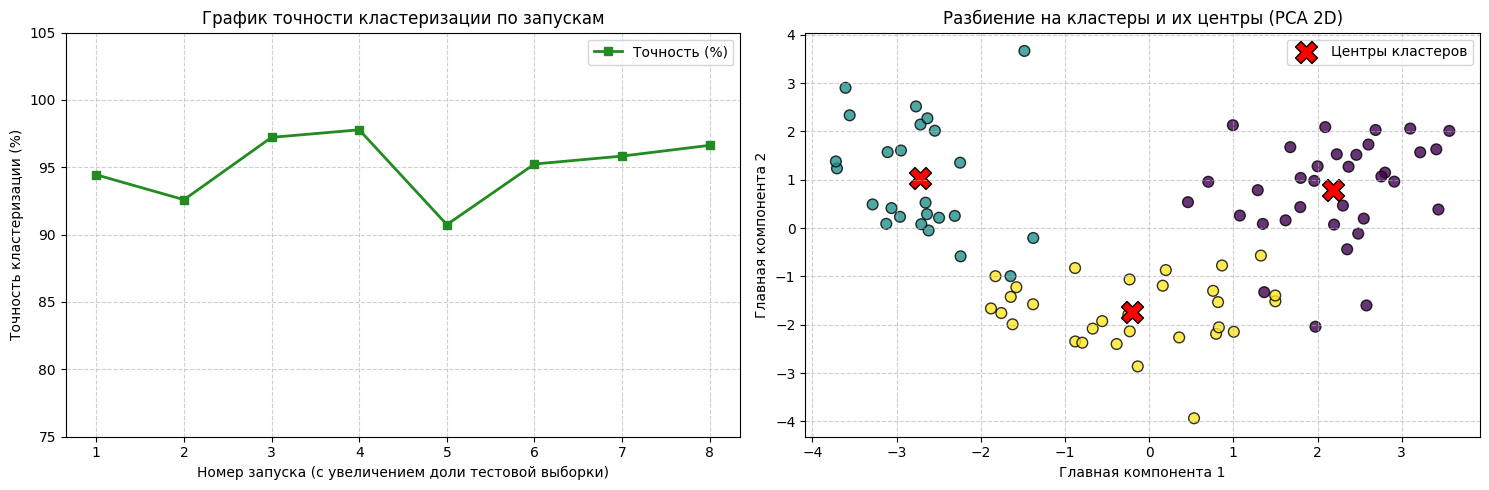

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График 1: Точность кластеризации и соотношение правильных/неправильных объектов
x_runs = results_df['№ запуска']
axes[0].plot(
    x_runs,
    results_df['Точность (%)'],
    marker='s',
    color='forestgreen',
    linewidth=2,
    label='Точность (%)',
)
axes[0].set_title('График точности кластеризации по запускам')
axes[0].set_xlabel('Номер запуска (с увеличением доли тестовой выборки)')
axes[0].set_ylabel('Точность кластеризации (%)')
axes[0].set_ylim(75, 105)
axes[0].set_xticks(x_runs)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# График 2: Визуализация центров и разбиения кластеров на плоскости (PCA)
pca = PCA(n_components=2)
X_tr_2d = pca.fit_transform(X_tr_std)
cents_2d = pca.transform(cents)

scatter = axes[1].scatter(
    X_tr_2d[:, 0],
    X_tr_2d[:, 1],
    c=tr_labels,
    cmap='viridis',
    s=60,
    edgecolors='k',
    alpha=0.8,
)
axes[1].scatter(
    cents_2d[:, 0],
    cents_2d[:, 1],
    c='red',
    marker='X',
    s=250,
    edgecolors='black',
    label='Центры кластеров',
)
axes[1].set_title('Разбиение на кластеры и их центры (PCA 2D)')
axes[1].set_xlabel('Главная компонента 1')
axes[1].set_ylabel('Главная компонента 2')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()
